In [3]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

num_cities = 15
city_coords = np.random.rand(num_cities, 2) * 100

dist_matrix = np.zeros((num_cities, num_cities))
for i in range(num_cities):
    for j in range(num_cities):
        dist_matrix[i, j] = np.linalg.norm(city_coords[i] - city_coords[j])

def calculate_tour_distance(position):
    tour = np.argsort(position)
    distance = 0.0
    for i in range(num_cities):
        from_city = tour[i]
        to_city = tour[(i + 1) % num_cities]
        distance += dist_matrix[from_city, to_city]
    return distance, tour

def gwo_tsp(num_wolves, max_iter):
    dim = num_cities
    lb = -10.0
    ub = 10.0

    positions = np.random.uniform(lb, ub, (num_wolves, dim))

    alpha_pos = np.zeros(dim)
    alpha_score = float('inf')
    alpha_tour = []

    beta_pos = np.zeros(dim)
    beta_score = float('inf')

    delta_pos = np.zeros(dim)
    delta_score = float('inf')

    convergence_curve = []

    for l in range(max_iter):
        for i in range(num_wolves):
            positions[i, :] = np.clip(positions[i, :], lb, ub)

            fitness, tour = calculate_tour_distance(positions[i, :])

            if fitness < alpha_score:
                alpha_score = fitness
                alpha_pos = positions[i, :].copy()
                alpha_tour = tour.copy()

            elif fitness < beta_score:
                beta_score = fitness
                beta_pos = positions[i, :].copy()

            elif fitness < delta_score:
                delta_score = fitness
                delta_pos = positions[i, :].copy()

        a = 2 - l * (2 / max_iter)

        for i in range(num_wolves):
            for j in range(dim):
                r1, r2 = np.random.rand(), np.random.rand()
                A1 = 2 * a * r1 - a
                C1 = 2 * r2
                D_alpha = abs(C1 * alpha_pos[j] - positions[i, j])
                X1 = alpha_pos[j] - A1 * D_alpha

                r1, r2 = np.random.rand(), np.random.rand()
                A2 = 2 * a * r1 - a
                C2 = 2 * r2
                D_beta = abs(C2 * beta_pos[j] - positions[i, j])
                X2 = beta_pos[j] - A2 * D_beta

                r1, r2 = np.random.rand(), np.random.rand()
                A3 = 2 * a * r1 - a
                C3 = 2 * r2
                D_delta = abs(C3 * delta_pos[j] - positions[i, j])
                X3 = delta_pos[j] - A3 * D_delta

                positions[i, j] = (X1 + X2 + X3) / 3

        convergence_curve.append(alpha_score)

    return alpha_tour, alpha_score, convergence_curve

best_tour, best_distance, history = gwo_tsp(num_wolves=30, max_iter=200)
print(f"Best Tour (City Visit Order): {best_tour}")
print(f"Best Tour Distance: {best_distance:.2f}")

Best Tour (City Visit Order): [ 8  2  7  9 14 10  6  1  4 13  3  5  0 12 11]
Best Tour Distance: 398.03


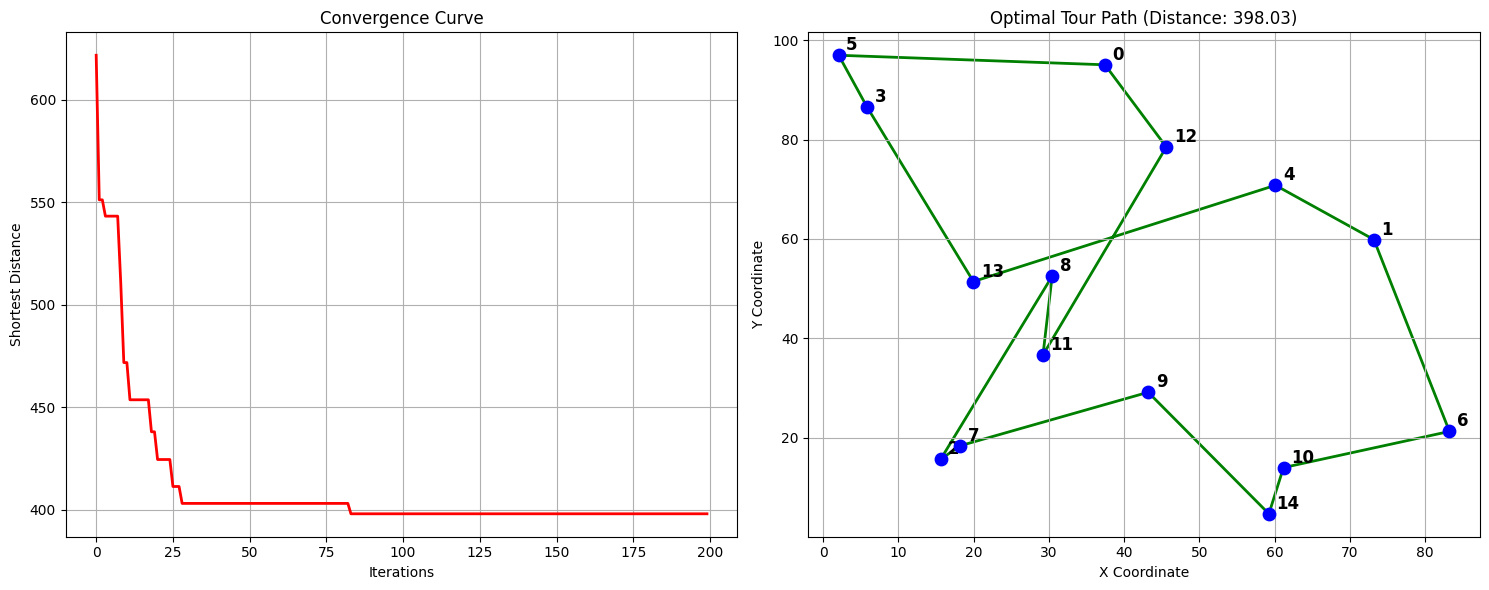

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].plot(history, color='red', linewidth=2)
axes[0].set_title("Convergence Curve")
axes[0].set_xlabel("Iterations")
axes[0].set_ylabel("Shortest Distance")
axes[0].grid(True)

tour_coords = city_coords[best_tour]
tour_coords = np.vstack([tour_coords, tour_coords[0]])

axes[1].scatter(city_coords[:, 0], city_coords[:, 1], color='blue', s=80, zorder=5)
for i, (x, y) in enumerate(city_coords):
    axes[1].text(x + 1, y + 1, str(i), fontsize=12, fontweight='bold')

axes[1].plot(tour_coords[:, 0], tour_coords[:, 1], color='green', linestyle='-', linewidth=2, zorder=1)
axes[1].set_title(f"Optimal Tour Path (Distance: {best_distance:.2f})")
axes[1].set_xlabel("X Coordinate")
axes[1].set_ylabel("Y Coordinate")
axes[1].grid(True)

plt.tight_layout()
plt.show()